# Comparación de los tres modelos

SARIMAX, XGBoost y la LSTM en el test, en las mismas filas: los mismos días de pronóstico, horas y
horizontes, con el mismo precio real y los mismos ingenuos. No se entrena ningún modelo; se leen
los pronósticos guardados de cada uno en `datos/resultados/`.

Periodos de test: 2023-2025 y 2026 hasta el 6 de octubre. Cada modelo pronostica desde cada día
$t$ los horizontes $h = 3$ a $9$, la semana siguiente al día del pronóstico, con las 24 horas de
cada día.

Primero va el criterio de la tesis, que se mide en logaritmo. Después los resultados se presentan
como en Salazar-Peña et al. (2025): las métricas de error en COP/kWh por horizonte con intervalo
de 95%, el nRMSE, el skill score frente al ingenuo del día, el MAPE por hora del día, el mejor
pronóstico en cada horizonte y hora, y semanas de ejemplo con la correlación de Pearson entre el
pronóstico y el precio real. Al final, la comparación directa entre modelos y la división del
error entre el nivel y la forma del día.

In [1]:
from pathlib import Path
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle

# pandas 2.3 con numpy 2.5 avisa por una unidad interna de las fechas; no cambia nada
warnings.filterwarnings("ignore", message="The 'generic' unit for NumPy timedelta")

RAIZ = Path("datos")
PANELES = RAIZ / "paneles"
XGB = RAIZ / "resultados" / "modelo_xgboost"
SAR = RAIZ / "resultados" / "modelo_sarimax"
LSTM = RAIZ / "resultados" / "modelo_lstm_bloques"
HS = list(range(3, 10))

COLOR = {"precio real": "#2a78d6", "SARIMAX": "#1baf7a", "XGBoost": "#eb6834", "LSTM": "#eda100",
         "ingenuo del día": "#898781", "ingenuo semanal": "#c3c2b7"}
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": "white", "axes.grid": True,
                     "grid.color": "#e5e4df", "axes.edgecolor": "#c3c2b7", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlelocation": "left", "axes.titlesize": 11,
                     "legend.frameon": False})
pd.set_option("display.precision", 3)

Las funciones de medición son las mismas de los otros notebooks: `criterio` y `diebold_mariano`
para el criterio de la tesis, y `metricas`, `por_horizonte` y `figura_semana` para el formato del
paper.

In [2]:
BLOQUES = {"h = 3 a 9": HS, "h = 3": [3], "h = 3 a 7": [3, 4, 5, 6, 7], "h = 8 a 9": [8, 9]}


def rmse(e):
    return float(np.sqrt(np.mean(np.square(e))))


def newey_west(d, L):
    # media de una serie diaria y su error estándar con L rezagos
    u = d - d.mean()
    v = np.mean(u * u)
    for l in range(1, min(L, len(d) - 1) + 1):
        v += 2 * (1 - l / (L + 1)) * np.mean(u[l:] * u[:-l])
    return d.mean(), np.sqrt(v / len(d))


def diebold_mariano(e_a, e_b, fechas, L):
    # t negativo: a tiene menos error que b
    dif = np.square(np.asarray(e_a)) - np.square(np.asarray(e_b))
    d = pd.Series(dif).groupby(np.asarray(fechas)).mean().to_numpy()
    m, ee = newey_west(d, L)
    return m / ee, 2 * stats.norm.sf(abs(m / ee))


def criterio(g, pron="y_hat", bloques=BLOQUES):
    filas = []
    for nombre, hs in bloques.items():
        b = g[g["h"].isin(hs)]
        e = b["y"] - b[pron]
        ingenuos = {"del día": b["y"], "semanal": b["y"] - b["y_semanal"]}
        ref = min(ingenuos, key=lambda k: rmse(ingenuos[k]))
        t, p = diebold_mariano(e, ingenuos[ref], b["fecha"], max(hs) - 1 + 7)
        mejora = 100 * (1 - rmse(e) / rmse(ingenuos[ref]))
        filas.append({"bloque": nombre, "RMSE": rmse(e), "ingenuo": ref, "RMSE ingenuo": rmse(ingenuos[ref]),
                      "mejora (%)": mejora, "t": t, "p": p, "cumple": bool(mejora >= 5 and p < 0.05)})
    return pd.DataFrame(filas).set_index("bloque")

# El error es pronóstico menos real, en COP/kWh: un MBE negativo quiere decir que el modelo
# se quedó por debajo del precio real.
AZULES = ["#86b6ef", "#6da7ec", "#5598e7", "#3987e5", "#256abf", "#184f95", "#0d366b"]
COLOR_METRICA = {"MAE": "#5598e7", "RMSE": "#0d366b", "MBE": "#52514e"}
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
EJE_H = "h (días desde el último precio conocido)"


def metricas(g, pron):
    e = g[pron] - g["real"]
    r = np.sqrt(np.mean(e ** 2))
    return pd.Series({"MAE": e.abs().mean(), "RMSE": r, "nRMSE (%)": 100 * r / g["real"].mean(),
                      "MBE": e.mean(), "MAPE (%)": 100 * (e.abs() / g["real"]).mean()})


def por_horizonte(g, pron):
    # el intervalo t al 95% se calcula con el error promedio de cada día de pronóstico,
    # porque las 24 horas de un mismo día no son independientes
    filas = {}
    for h, x in g.groupby("h"):
        e = x[pron] - x["real"]
        dia = pd.DataFrame({"MAE": e.abs(), "MBE": e, "MSE": e ** 2}).groupby(x["fecha"]).mean()
        media = dia.mean()
        margen = stats.t.ppf(0.975, len(dia) - 1) * dia.std() / np.sqrt(len(dia))
        f = {}
        for m in ["MAE", "MBE", "MSE"]:
            f[m], f[m + " inf"], f[m + " sup"] = media[m], media[m] - margen[m], media[m] + margen[m]
        for c in ["", " inf", " sup"]:
            f["RMSE" + c] = np.sqrt(max(f["MSE" + c], 0))
            f["nRMSE" + c] = 100 * f["RMSE" + c] / x["real"].mean()
        f["MAPE"] = 100 * (e.abs() / x["real"]).mean()
        filas[h] = f
    return pd.DataFrame(filas).T


def figura_error(tablas, modelo):
    # como las figuras 15, 18 y 21 del paper
    fig, ejes = plt.subplots(1, len(tablas), figsize=(11, 3.8), sharey=True)
    for ax, (periodo, r) in zip(ejes, tablas.items()):
        ax.axhline(0, color="#898781", lw=0.8)
        for m in ["MAE", "RMSE", "MBE"]:
            ax.errorbar(r.index, r[m], yerr=[r[m] - r[m + " inf"], r[m + " sup"] - r[m]], color=COLOR_METRICA[m],
                        marker="o", ms=4, capsize=3, label=m)
        ax.set_title(periodo)
        ax.set_xticks(HS)
        ax.set_xlabel(EJE_H)
    ejes[0].set_ylabel("COP/kWh")
    ejes[0].legend()
    fig.suptitle(f"{modelo}: error por horizonte, con intervalo de 95%", x=0.01, ha="left", fontsize=11)
    plt.tight_layout()
    plt.show()


def figura_nrmse(tablas, colores, modelo):
    # como las figuras 16, 19 y 22 del paper
    fig, ax = plt.subplots(figsize=(8, 3.6))
    for periodo, r in tablas.items():
        ax.plot(r.index, r["nRMSE"], color=colores[periodo], marker="o", ms=4, label=periodo)
        ax.fill_between(r.index, r["nRMSE inf"], r["nRMSE sup"], color=colores[periodo], alpha=0.2, lw=0)
    ax.set_xticks(HS)
    ax.set_xlabel(EJE_H)
    ax.set_ylabel("%")
    ax.set_title(f"{modelo}: nRMSE por horizonte, con intervalo de 95%")
    ax.legend()
    plt.show()


def figura_mape_hora(g, pron, modelo):
    # como las figuras 17, 20 y 23 del paper: una curva por horizonte, de h = 3 (clara) a h = 9 (oscura)
    fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
    for ax, (periodo, x) in zip(ejes, g.groupby("periodo")):
        mape = (100 * (x[pron] - x["real"]).abs() / x["real"]).groupby([x["hora"], x["h"]]).mean().unstack("h")
        for h, c in zip(HS, AZULES):
            ax.plot(mape.index, mape[h], color=c, lw=1.5, label=f"h = {h}")
        ax.set_title(periodo)
        ax.set_xticks([1, 4, 8, 12, 16, 20, 24])
        ax.set_xlabel("hora del día")
    ejes[0].set_ylabel("MAPE (%)")
    ejes[1].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.suptitle(f"{modelo}: MAPE por hora del día y horizonte", x=0.01, ha="left", fontsize=11)
    plt.tight_layout()
    plt.show()


def figura_semana(s, columnas, titulo, nivel=None):
    # como las figuras 28 a 37 del paper: el pronóstico frente al real y su correlación de Pearson.
    # nivel = (nombre, valor) agrega una línea horizontal de referencia
    s = s.sort_values("momento")
    previo = s.drop_duplicates("hora").sort_values("hora")
    momento_previo = previo["t"] + pd.to_timedelta(previo["hora"] - 1, unit="h")
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [2.6, 1]})
    a1.plot(momento_previo, previo["ingenuo del día"], color="#52514e", lw=1.3, label="último día conocido")
    a1.plot(s["momento"], s["real"], color=COLOR["precio real"], lw=2, label="precio real")
    for c in columnas:
        estilo = {"ls": "--", "lw": 1.1} if c.startswith("ingenuo") else {"lw": 1.4}
        a1.plot(s["momento"], s[c], color=COLOR[c], label=c, **estilo)
        r = np.corrcoef(s["real"], s[c])[0, 1]
        a2.scatter(s[c], s["real"], s=8, color=COLOR[c], alpha=0.7, label=f"{c}, r = {r:.2f}".replace(".", ","))
    if nivel:
        a1.axhline(nivel[1], color="#52514e", ls=(0, (1, 2)), lw=1.5, label=nivel[0])
    lim = [s[columnas + ["real"]].min().min(), s[columnas + ["real"]].max().max()]
    a2.plot(lim, lim, color="#898781", lw=0.8)
    dias = pd.date_range(previo["t"].iloc[0], s["momento"].max().normalize())
    a1.set_xticks(dias, [f"{x.day} {MESES[x.month - 1]}" for x in dias])
    a1.set_ylabel("COP/kWh")
    a1.set_title(titulo)
    a1.legend(ncol=3, fontsize=8)
    a2.set_xlabel("pronóstico (COP/kWh)")
    a2.set_ylabel("precio real (COP/kWh)")
    a2.set_title("Pronóstico frente al real")
    a2.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

In [3]:
partes = [pd.read_csv(XGB / f"prueba_h{h}.csv.gz").assign(periodo="2023-2025") for h in HS]
partes.append(pd.read_csv(XGB / "prueba2026_mensual.csv.gz").query("3 <= h <= 9").assign(periodo="2026"))
xgb_test = pd.concat(partes, ignore_index=True)

sar = pd.concat([pd.read_csv(SAR / "prueba_2023_2025.csv.gz"), pd.read_csv(SAR / "prueba_2026.csv.gz")])
lstm = pd.concat([pd.read_csv(LSTM / "prueba_2023_2025.csv.gz"), pd.read_csv(LSTM / "prueba_2026.csv.gz")])

claves = ["fecha", "hora", "h"]
d = (xgb_test.rename(columns={"y_hat": "XGBoost"})
     .merge(sar[claves + ["lp_hat"]], on=claves, validate="one_to_one")
     .merge(lstm.rename(columns={"y_hat": "LSTM"}), on=claves, validate="one_to_one"))
assert len(d) == len(xgb_test) == len(sar) == len(lstm)

# SARIMAX pronostica el nivel del logaritmo; se pasa al mismo cambio y de los otros dos
d["SARIMAX"] = d["lp_hat"] - np.log(d["precio_t"])
d["fecha"] = pd.to_datetime(d["fecha"])
MODELOS = ["SARIMAX", "XGBoost", "LSTM"]
TODOS = MODELOS + ["ingenuo del día", "ingenuo semanal"]
PERIODOS = ["2023-2025", "2026"]

# los mismos pronósticos en COP/kWh
pz = d[["periodo", "fecha", "hora", "h"]].assign(
    real=d["precio_t"] * np.exp(d["y"]), **{m: d["precio_t"] * np.exp(d[m]) for m in MODELOS},
    **{"ingenuo del día": d["precio_t"], "ingenuo semanal": d["precio_t"] * np.exp(d["y_semanal"])})

d.groupby("periodo").agg(**{"pronósticos": ("y", "size"), "primer día": ("fecha", "min"), "último día": ("fecha", "max")})

,pronósticos,primer día,último día
periodo,,,
2023-2025,183120,2023-01-01,2025-12-28
2026,45864,2026-01-01,2026-10-03


## 1. Criterio de la tesis

Un modelo funciona en un bloque de horizontes si su RMSE en logaritmo es al menos 5% menor que el
del mejor ingenuo y si la prueba de Diebold-Mariano (Diebold y Mariano, 1995) contra ese ingenuo da
$p < 0{,}05$, con varianza de Newey-West (Newey y West, 1987). En todos los bloques el mejor
ingenuo es el del día. Mejora en % frente a ese ingenuo:

In [4]:
crit = pd.concat({(p, m): criterio(g, m) for p, g in d.groupby("periodo") for m in MODELOS},
                 names=["periodo", "modelo"])
display(crit["mejora (%)"].unstack("bloque")[list(BLOQUES)].reindex(MODELOS, level="modelo").round(1))
print("Semana completa (h = 3 a 9):")
crit.xs("h = 3 a 9", level="bloque")[["RMSE", "RMSE ingenuo", "mejora (%)", "p", "cumple"]]

bloque             h = 3 a 9  h = 3  h = 3 a 7  h = 8 a 9
periodo   modelo                                         
2023-2025 SARIMAX        6.4    7.7        6.4        6.4
          XGBoost       11.6   17.9       12.5       10.1
          LSTM          14.9   24.5       17.5       10.6
2026      SARIMAX        5.6    6.5        5.6        5.6
          XGBoost       10.0   19.5       11.6        7.2
          LSTM          19.7   27.9       21.6       16.5

Semana completa (h = 3 a 9):


RMSE  RMSE ingenuo  mejora (%)          p  cumple
periodo   modelo                                                     
2023-2025 SARIMAX  0.470         0.502       6.409  1.612e-10    True
          XGBoost  0.443         0.502      11.638  1.407e-06    True
          LSTM     0.427         0.502      14.880  3.889e-06    True
2026      SARIMAX  0.411         0.435       5.590  4.188e-04    True
          XGBoost  0.392         0.435       9.962  1.013e-03    True
          LSTM     0.350         0.435      19.711  2.533e-04    True

Los tres modelos cumplen el criterio en todos los bloques y en los dos periodos. El orden es el
mismo en los dos: la LSTM tiene la mayor mejora en la semana (14,9% y 19,7%), después XGBoost
(11,6% y 10,0%) y después SARIMAX (6,4% y 5,6%). La mejora en cada horizonte:

In [5]:
por_h = pd.DataFrame({(p, m): g.groupby("h").apply(lambda x: 100 * (1 - rmse(x["y"] - x[m]) / rmse(x["y"])), include_groups=False)
                      for p, g in d.groupby("periodo") for m in MODELOS})
por_h.round(1)

2023-2025                  2026              
    SARIMAX XGBoost  LSTM SARIMAX XGBoost  LSTM
h                                              
3       7.7    17.9  24.5     6.5    19.5  27.9
4       7.4    15.7  21.9     6.5    16.5  26.1
5       7.1    15.1  18.7     6.3    14.6  22.8
6       6.0     9.3  14.8     5.0     6.9  19.1
7       4.7     8.0  11.6     4.2     5.7  16.1
8       5.9     9.3  11.0     5.1     7.4  16.5
9       6.9    10.8  10.2     6.1     6.9  16.6

En logaritmo la LSTM tiene la mayor mejora en casi todos los horizontes; solo en $h = 9$ de
2023-2025 XGBoost queda un poco por encima. La distancia entre los modelos es más grande en los
primeros días de la semana, donde XGBoost y la LSTM aprovechan información de oferta, hidrología y
despacho que SARIMAX no usa.

## 2. Métricas de error en pesos

El precio se usa en pesos. El pronóstico en pesos es $\hat P = P(t,H)\,e^{\hat y}$ y el error es
el pronóstico menos el precio real, en COP/kWh: un MBE negativo quiere decir que el modelo se
quedó por debajo. El nRMSE es el RMSE dividido por el precio real promedio, y el skill score es la
mejora del RMSE en pesos frente al ingenuo del día, como en la figura 24 de Salazar-Peña et al.
(2025).

In [6]:
semana = pd.DataFrame({(p, m): metricas(g, m) for p, g in pz.groupby("periodo") for m in TODOS}).T
semana.index.names = ["periodo", "modelo"]
ref = semana.xs("ingenuo del día", level="modelo")["RMSE"]
semana["skill score (%)"] = 100 * (1 - semana["RMSE"] / ref.reindex(semana.index.get_level_values("periodo")).to_numpy())
semana.round(1)

MAE   RMSE  nRMSE (%)   MBE  MAPE (%)  \
periodo   modelo                                                     
2023-2025 SARIMAX          148.8  242.1       49.3 -15.3      39.0   
          XGBoost          148.6  247.5       50.4 -46.4      36.2   
          LSTM             138.9  238.9       48.6 -33.1      34.1   
          ingenuo del día  150.1  257.1       52.3   1.3      40.1   
          ingenuo semanal  172.1  286.3       58.2   1.8      46.8   
2026      SARIMAX          122.9  176.5       36.2 -29.2      30.4   
          XGBoost          122.5  175.7       36.0 -38.0      29.5   
          LSTM             114.5  172.0       35.2 -30.6      25.6   
          ingenuo del día  127.1  188.5       38.6  -8.3      32.4   
          ingenuo semanal  143.9  204.4       41.9 -13.0      37.2   

                           skill score (%)  
periodo   modelo                            
2023-2025 SARIMAX                      5.8  
          XGBoost                      3.7  
          LSTM                         7.1  
          ingenuo del día              0.0  
          ingenuo semanal            -11.4  
2026      SARIMAX                      6.4  
          XGBoost                      6.8  
          LSTM                         8.8  
          ingenuo del día              0.0  
          ingenuo semanal             -8.4

En pesos la LSTM sigue teniendo el menor MAE, RMSE y MAPE en los dos periodos (MAPE de 34,1% en
2023-2025, frente a 36,2% de XGBoost, 39,0% de SARIMAX y 40,1% del ingenuo del día). Pero las
ventajas en el RMSE son más pequeñas que en logaritmo: el skill score de la semana es 7,1% para la
LSTM, 5,8% para SARIMAX y 3,7% para XGBoost en 2023-2025, y 8,8%, 6,4% y 6,8% en 2026. SARIMAX
queda por delante de XGBoost en 2023-2025.

La diferencia está en el MBE. Los tres modelos se quedan cortos en promedio, entre 15 y 46
COP/kWh en 2023-2025, mientras el ingenuo del día casi no tiene sesgo. Los tres pronostican el
cambio en logaritmo, y al volver a pesos $e^{\hat y}$ se acerca a la mediana del precio, que queda
por debajo de la media porque el precio tiene picos hacia arriba (Duan, 1983). Además, en pesos
pesan más los errores de los meses caros. El ingenuo semanal tiene el mayor MAE, RMSE y MAPE en
los dos periodos.

## 3. Error por horizonte

Como en las figuras 15, 18 y 21 del paper: el MAE, el RMSE y el MBE en cada horizonte, con un
intervalo t al 95%. El intervalo se calcula con el error promedio de cada día de pronóstico,
porque las 24 horas de un mismo día no son independientes. La línea punteada es el ingenuo del
día.

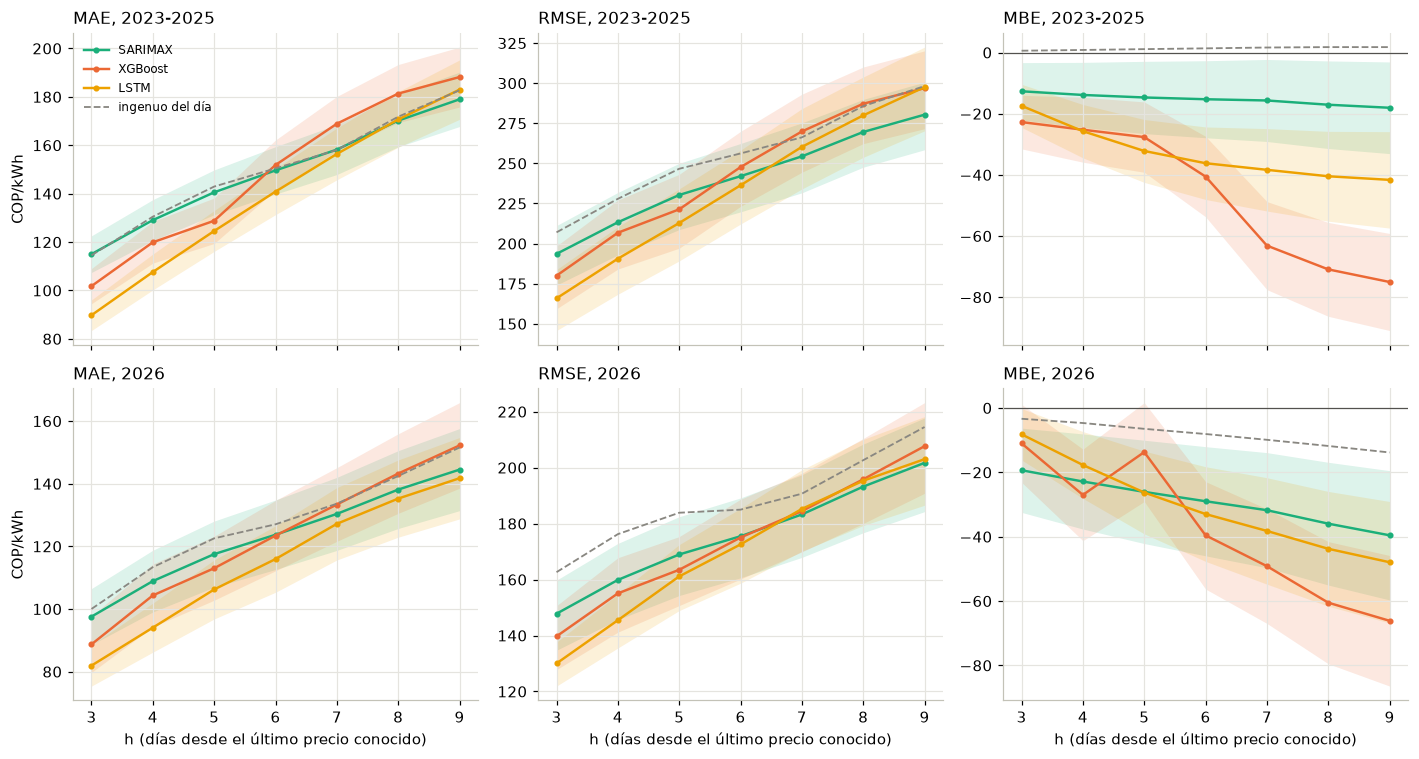

2023-2025                2026             
                        MAE   RMSE   MBE    MAE   RMSE   MBE
modelo          h                                           
SARIMAX         3     115.0  193.6 -12.7   97.6  147.8 -19.4
                4     129.1  213.3 -13.9  108.9  159.9 -22.8
                5     140.6  230.3 -14.7  117.5  169.0 -26.1
                6     149.6  242.0 -15.3  123.7  175.5 -29.0
                7     158.2  254.4 -15.7  130.4  183.3 -31.8
                8     170.2  269.6 -17.1  138.1  193.2 -35.9
                9     179.0  280.4 -18.1  144.5  201.7 -39.6
XGBoost         3     101.8  180.0 -22.7   88.7  139.7 -11.0
                4     119.9  206.8 -25.2  104.3  155.1 -27.0
                5     128.8  221.4 -27.7  113.0  163.5 -13.7
                6     151.8  247.7 -40.6  123.4  175.0 -39.6
                7     168.9  269.9 -63.1  133.4  184.5 -49.2
                8     181.3  287.2 -70.9  143.2  195.8 -60.5
                9     188.2  296.9 -75.0  152.2  207.7 -66.1
LSTM            3      89.8  165.9 -17.4   81.9  130.0  -8.2
                4     107.6  190.6 -25.7   94.1  145.5 -17.7
                5     124.6  212.8 -32.2  106.3  161.1 -26.3
                6     140.8  236.3 -36.2  116.0  172.6 -33.0
                7     156.4  260.3 -38.4  127.2  185.2 -38.2
                8     170.7  279.9 -40.5  135.3  195.3 -43.8
                9     183.0  297.6 -41.6  141.8  203.0 -47.9
ingenuo del día 3     114.5  207.0   0.6  100.0  162.6  -3.3
                4     130.5  227.9   0.8  113.4  176.2  -4.7
                5     142.9  246.7   1.1  122.6  183.9  -6.5
                6     150.4  256.2   1.4  127.0  185.0  -8.1
                7     158.1  266.2   1.6  133.6  190.7  -9.9
                8     171.8  285.7   1.8  142.5  202.6 -11.8
                9     182.7  298.2   1.8  151.6  214.5 -13.8

In [7]:
tablas = {(p, m): por_horizonte(g, m) for p, g in pz.groupby("periodo") for m in MODELOS + ["ingenuo del día"]}

fig, ejes = plt.subplots(2, 3, figsize=(13, 7), sharex=True)
for fila, p in zip(ejes, PERIODOS):
    for ax, met in zip(fila, ["MAE", "RMSE", "MBE"]):
        for m in MODELOS + ["ingenuo del día"]:
            r = tablas[(p, m)]
            if m in MODELOS:
                ax.plot(r.index, r[met], color=COLOR[m], lw=1.6, marker="o", ms=3, label=m)
                ax.fill_between(r.index, r[met + " inf"], r[met + " sup"], color=COLOR[m], alpha=0.15, lw=0)
            else:
                ax.plot(r.index, r[met], color=COLOR[m], lw=1.2, ls="--", label=m)
        if met == "MBE":
            ax.axhline(0, color="#52514e", lw=0.8)
        ax.set_title(f"{met}, {p}")
        ax.set_xticks(HS)
    fila[0].set_ylabel("COP/kWh")
for ax in ejes[1]:
    ax.set_xlabel(EJE_H)
ejes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

pd.concat({m: pd.concat({p: tablas[(p, m)][["MAE", "RMSE", "MBE"]] for p in PERIODOS}, axis=1)
           for m in MODELOS + ["ingenuo del día"]}, names=["modelo", "h"]).round(1)

La LSTM y XGBoost tienen menos error que el ingenuo en los primeros horizontes: en 2023-2025, en
$h = 3$, el MAE es 89,8 COP/kWh para la LSTM y 101,8 para XGBoost, frente a 114,5 del ingenuo.
SARIMAX tiene casi el mismo MAE que el ingenuo en todos los horizontes de 2023-2025 (115,0 en
$h = 3$); su ventaja está en el RMSE, que pesa más los errores grandes. Con el horizonte la
distancia se cierra, y desde $h = 7$ SARIMAX tiene el menor RMSE en los dos periodos: su ventaja
casi no cambia con el horizonte, mientras la de XGBoost y la LSTM se pierde. El MBE de los tres
modelos es negativo en todos los horizontes; el de XGBoost es el que más crece, de $-23$ a $-75$
COP/kWh en 2023-2025.

Los intervalos son anchos: el del MAE tiene una semiamplitud de 6 a 14 COP/kWh y el del RMSE una
amplitud de 37 a 52 COP/kWh en 2023-2025. Los de la LSTM y XGBoost se cruzan en todos los
horizontes. Que los intervalos se crucen no quiere decir que los modelos no se distingan: los tres
pronostican los mismos días y sus errores suben y bajan juntos. Para comparar dos modelos se usa
la prueba de Diebold-Mariano sobre la diferencia de sus errores, en la sección 8.

## 4. nRMSE y skill score

El nRMSE por horizonte, como en las figuras 16, 19 y 22 del paper, y el skill score frente al
ingenuo del día, como en la figura 24. Línea continua: 2023-2025; punteada: 2026.

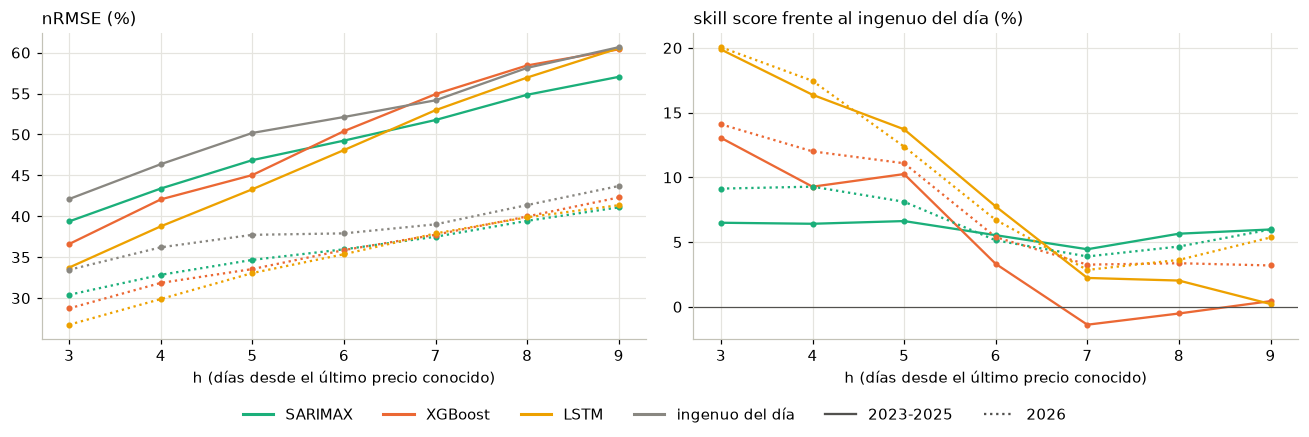

nRMSE (%)                                                      \
  2023-2025                                  2026                 
    SARIMAX XGBoost  LSTM ingenuo del día SARIMAX XGBoost  LSTM   
3      39.4    36.6  33.7            42.1    30.4    28.7  26.8   
4      43.4    42.1  38.8            46.4    32.8    31.9  29.9   
5      46.9    45.0  43.3            50.2    34.7    33.6  33.1   
6      49.2    50.4  48.1            52.1    36.0    35.9  35.4   
7      51.8    54.9  53.0            54.2    37.5    37.7  37.9   
8      54.9    58.4  57.0            58.1    39.4    40.0  39.9   
9      57.0    60.4  60.5            60.7    41.1    42.3  41.4   

                  skill score (%)                                      
                        2023-2025                  2026                
  ingenuo del día         SARIMAX XGBoost  LSTM SARIMAX XGBoost  LSTM  
3            33.5             6.5    13.1  19.9     9.1    14.1  20.1  
4            36.2             6.4     9.3  16.4     9.3    12.0  17.5  
5            37.7             6.6    10.3  13.7     8.1    11.1  12.4  
6            37.9             5.5     3.3   7.8     5.1     5.4   6.7  
7            39.0             4.4    -1.4   2.2     3.9     3.3   2.8  
8            41.4             5.6    -0.5   2.0     4.7     3.4   3.6  
9            43.7             6.0     0.4   0.2     6.0     3.2   5.4

In [8]:
skill = pd.DataFrame({(p, m): 100 * (1 - tablas[(p, m)]["RMSE"] / tablas[(p, "ingenuo del día")]["RMSE"])
                      for p in PERIODOS for m in MODELOS})

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
for p, estilo in zip(PERIODOS, ["-", ":"]):
    for m in MODELOS + ["ingenuo del día"]:
        a1.plot(HS, tablas[(p, m)]["nRMSE"], color=COLOR[m], ls=estilo, marker="o", ms=3)
        if m in MODELOS:
            a2.plot(HS, skill[(p, m)], color=COLOR[m], ls=estilo, marker="o", ms=3)
a2.axhline(0, color="#52514e", lw=0.8)
a1.set_title("nRMSE (%)")
a2.set_title("skill score frente al ingenuo del día (%)")
for ax in (a1, a2):
    ax.set_xticks(HS)
    ax.set_xlabel(EJE_H)
lineas = [Line2D([], [], color=COLOR[m], lw=2, label=m) for m in MODELOS + ["ingenuo del día"]]
lineas += [Line2D([], [], color="#52514e", ls=e, label=p) for p, e in zip(PERIODOS, ["-", ":"])]
fig.legend(handles=lineas, ncol=6, loc="lower center")
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

pd.concat({"nRMSE (%)": pd.DataFrame({(p, m): tablas[(p, m)]["nRMSE"] for p in PERIODOS for m in MODELOS + ["ingenuo del día"]}),
           "skill score (%)": skill}, axis=1).round(1)

En 2023-2025 el nRMSE va de 34% en $h = 3$ a 61% en $h = 9$ para la LSTM, de 37% a 60% para
XGBoost y de 39% a 57% para SARIMAX; en 2026 es más bajo para todos. El skill score muestra dos
comportamientos. La LSTM y XGBoost tienen su mayor ventaja en $h = 3$ (20% y 13% en 2023-2025) y
la pierden casi toda entre $h = 7$ y $h = 9$. La ventaja de SARIMAX cambia mucho menos con el
horizonte: entre 4% y 7% en 2023-2025 y entre 4% y 9% en 2026. En logaritmo la LSTM conserva al
final de la semana una mejora cercana al 10% (sección 1); en pesos no, porque ahí pesan más los
días caros y el sesgo crece con el horizonte.

## 5. MAPE por hora del día

El MAPE de cada modelo por hora del día, con los siete horizontes juntos. En los notebooks de cada
modelo está el mismo MAPE separado por horizonte, como en las figuras 17, 20 y 23 del paper.

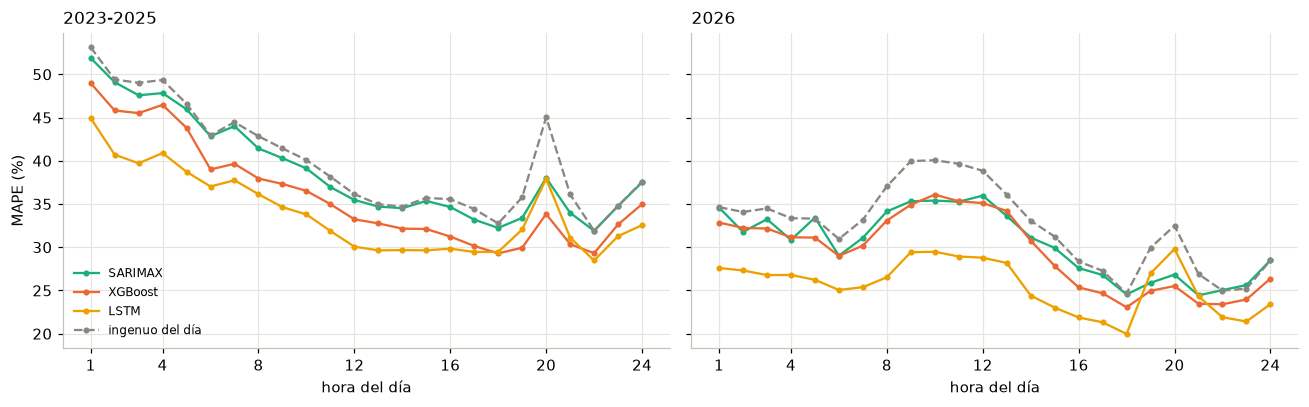

Horas del día en que cada modelo tiene el menor MAPE:


,2023-2025,2026
SARIMAX,0,0
XGBoost,4,3
LSTM,20,21


In [9]:
mape_hora = {p: pd.DataFrame({m: (100 * (g[m] - g["real"]).abs() / g["real"]).groupby(g["hora"]).mean()
                              for m in MODELOS + ["ingenuo del día"]})
             for p, g in pz.groupby("periodo")}

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (p, mh) in zip(ejes, mape_hora.items()):
    for m in mh:
        ax.plot(mh.index, mh[m], color=COLOR[m], marker="o", ms=3, label=m, ls="--" if m == "ingenuo del día" else "-")
    ax.set_title(p)
    ax.set_xticks([1, 4, 8, 12, 16, 20, 24])
    ax.set_xlabel("hora del día")
ejes[0].set_ylabel("MAPE (%)")
ejes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

print("Horas del día en que cada modelo tiene el menor MAPE:")
pd.DataFrame({p: mh[MODELOS].idxmin(axis=1).value_counts() for p, mh in mape_hora.items()}).reindex(MODELOS).fillna(0).astype(int)

En 2023-2025 el MAPE es más alto en la madrugada y más bajo al mediodía y en la tarde. La LSTM
tiene el menor MAPE en 20 de las 24 horas, y XGBoost en las otras cuatro, de la 18 a la 21, las del
pico de la noche. En esas horas el ingenuo del día tiene su mayor error (45% en la hora 20). En
2026 los errores más altos pasan a la mañana, entre las horas 8 y 12, y a la hora 20; la LSTM gana
21 horas y XGBoost de nuevo las de la noche, de la 19 a la 21.

## 6. Mejor pronóstico por horizonte y hora

Como en las figuras 10 a 12 de Salazar-Peña et al. (2025): para cada horizonte y hora del día, el
color de la celda es el error del mejor de los cinco pronósticos (los tres modelos y los dos
ingenuos) y el color del borde dice cuál fue. Periodo 2023-2025.

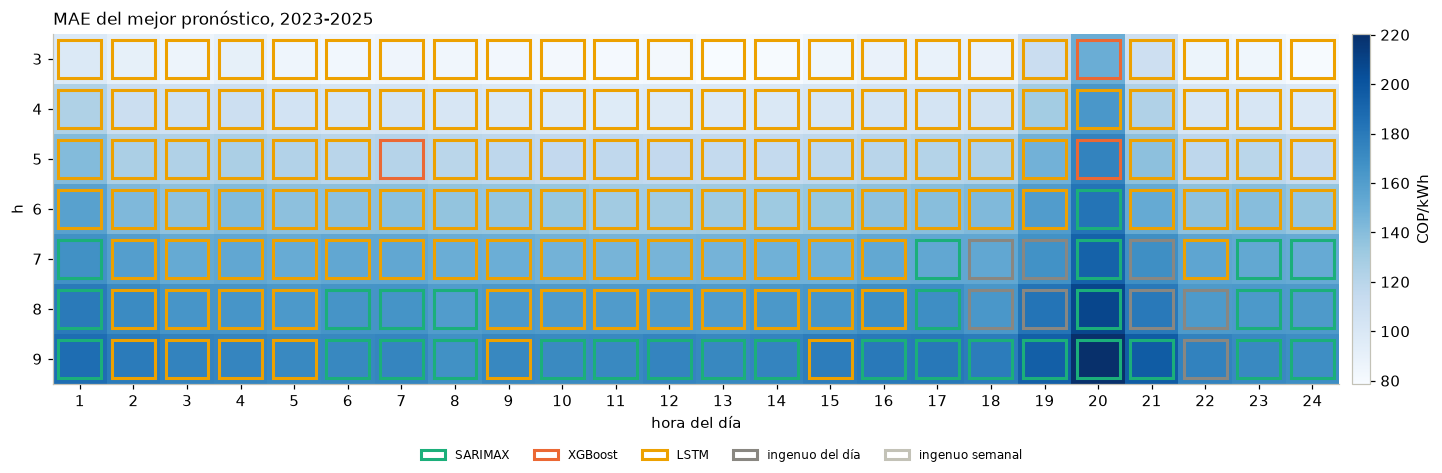

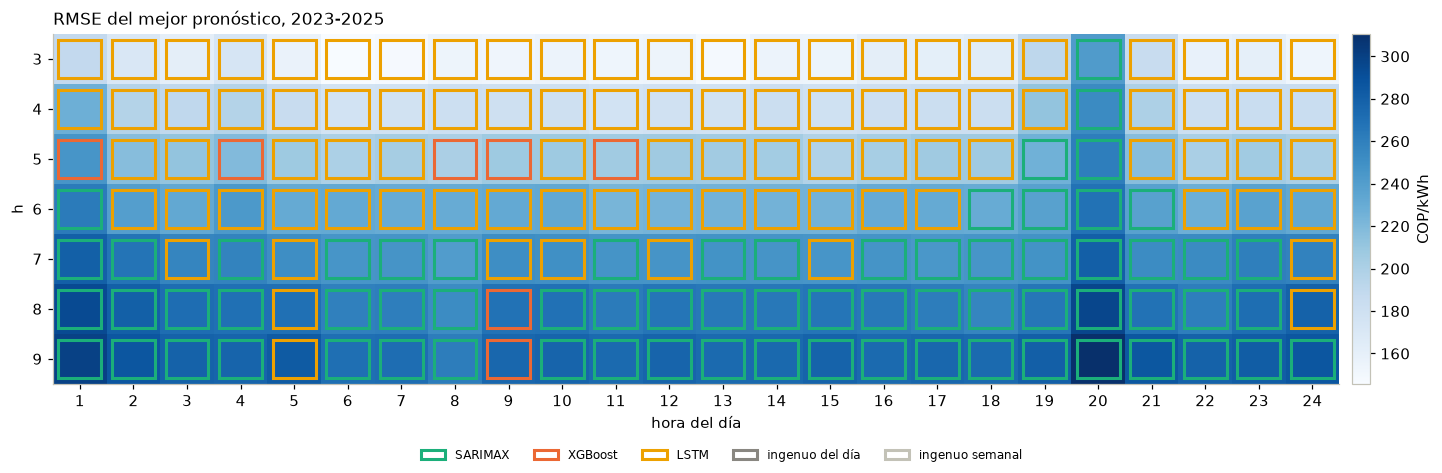

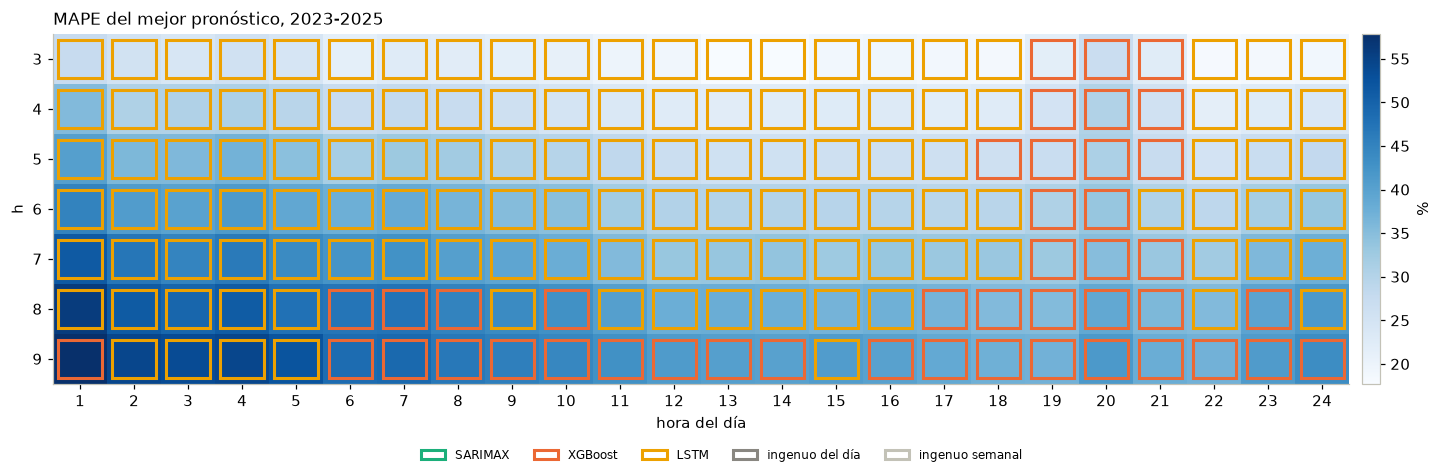

Celdas que gana cada pronóstico, de 168:


,MAE,RMSE,MAPE
SARIMAX,31,69,0
XGBoost,3,7,44
LSTM,126,92,124
ingenuo del día,8,0,0
ingenuo semanal,0,0,0


In [10]:
def mapa_mejor(valores, titulo, unidad):
    # valores: una fila por (h, hora) y una columna por pronóstico
    mejor = valores.idxmin(axis=1).unstack("hora")
    minimo = valores.min(axis=1).unstack("hora")
    fig, ax = plt.subplots(figsize=(13, 4.2), layout="constrained")
    im = ax.imshow(minimo.to_numpy(), cmap="Blues", aspect="auto")
    for i, h in enumerate(minimo.index):
        for j, hora in enumerate(minimo.columns):
            ax.add_patch(Rectangle((j - 0.4, i - 0.38), 0.8, 0.76, fill=False, lw=2,
                                   edgecolor=COLOR[mejor.loc[h, hora]]))
    ax.set_xticks(range(24), minimo.columns)
    ax.set_yticks(range(len(minimo.index)), minimo.index)
    ax.set_xlabel("hora del día")
    ax.set_ylabel("h")
    ax.grid(False)
    ax.set_title(titulo)
    fig.colorbar(im, ax=ax, label=unidad, pad=0.01)
    fig.legend(handles=[Patch(facecolor="white", edgecolor=COLOR[m], lw=2, label=m) for m in TODOS],
               ncol=5, loc="outside lower center", fontsize=8)
    plt.show()
    return pd.Series(mejor.to_numpy().ravel()).value_counts()


g = pz[pz["periodo"] == "2023-2025"]
error = {m: g[m] - g["real"] for m in TODOS}
por = [g["h"], g["hora"]]
ganadas = {
    "MAE": mapa_mejor(pd.DataFrame({m: error[m].abs().groupby(por).mean() for m in TODOS}),
                      "MAE del mejor pronóstico, 2023-2025", "COP/kWh"),
    "RMSE": mapa_mejor(pd.DataFrame({m: np.sqrt((error[m] ** 2).groupby(por).mean()) for m in TODOS}),
                       "RMSE del mejor pronóstico, 2023-2025", "COP/kWh"),
    "MAPE": mapa_mejor(pd.DataFrame({m: (100 * error[m].abs() / g["real"]).groupby(por).mean() for m in TODOS}),
                       "MAPE del mejor pronóstico, 2023-2025", "%"),
}
print("Celdas que gana cada pronóstico, de 168:")
pd.DataFrame(ganadas).reindex(TODOS).fillna(0).astype(int)

La LSTM es el mejor pronóstico en la mayoría de las celdas, sobre todo en los primeros horizontes:
126 de 168 en MAE, 92 en RMSE y 124 en MAPE. SARIMAX gana sobre todo de $h = 6$ a $9$, con 31
celdas en MAE y 69 en RMSE. XGBoost gana 44 celdas en MAPE, en las horas 19 a 21 y en buena parte
de $h = 8$ y $9$. El ingenuo del día gana 8 celdas en MAE, en la noche de los últimos horizontes.
En pesos los errores más altos están en la hora 20 y en los últimos horizontes; en porcentaje, en
la madrugada.

## 7. Semanas de ejemplo

El paper muestra días con poca, media y mucha nubosidad (figuras 28 a 37). Aquí se escogieron tres
semanas de 2023-2025 según el coeficiente de variación del precio real (la desviación estándar
sobre la media): la de menor variación, la mediana y la de mayor variación. A la derecha de cada
una está el pronóstico frente al real con la correlación de Pearson $r$. La línea gris oscura es el
último día conocido, el día $t$; entre ese día y la semana pronosticada quedan los dos días que
todavía no se conocen.

Cuando el precio real llega cerca del precio de escasez de activación que publica XM, la figura
lo marca con una línea punteada. Ese precio cambia cada mes y está en `datos/paneles/panel_diario.csv`.

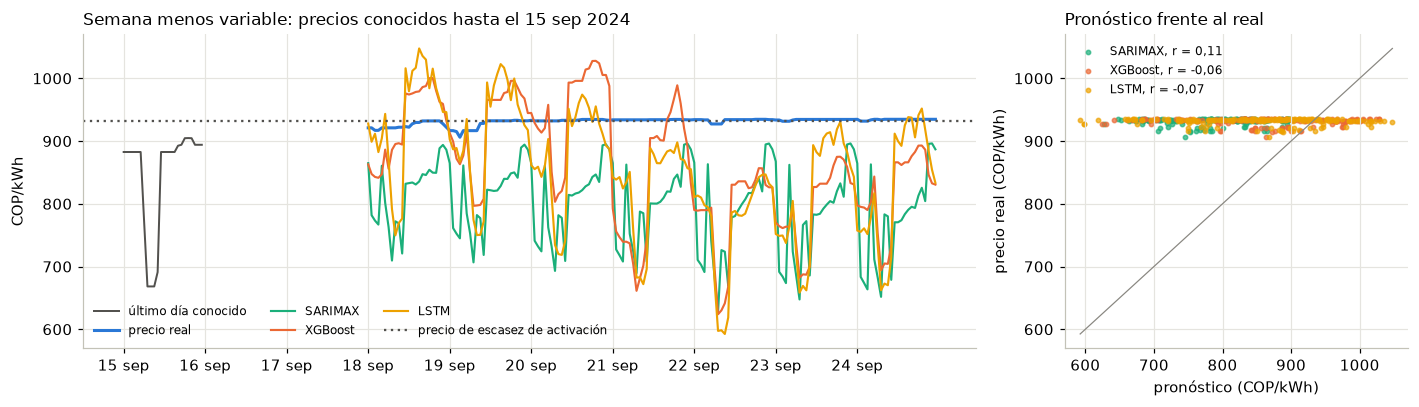

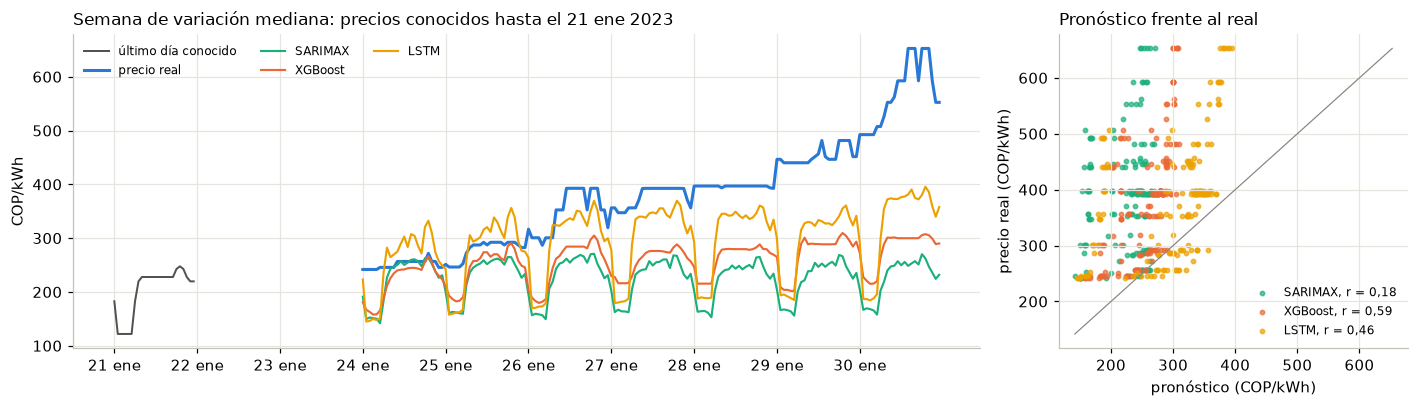

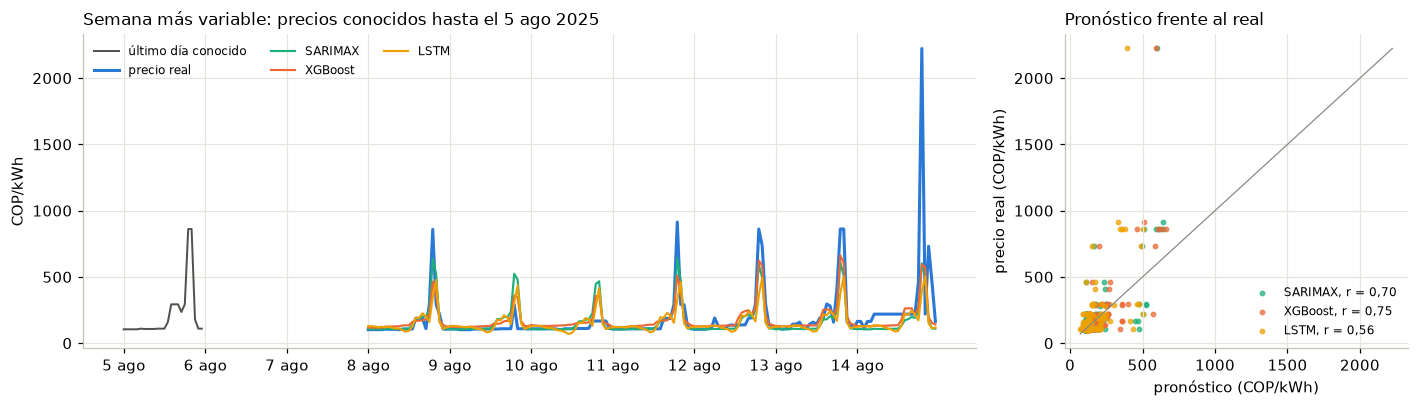

Semanas con el precio pegado al precio de escasez de activación: 36 de 1087


,semanas
mes del corte,
2023-09,24
2023-10,2
2024-04,1
2024-09,9


In [11]:
pea = pd.read_csv(PANELES / "panel_diario.csv", usecols=["fecha", "precio_esca_act"],
                  parse_dates=["fecha"]).set_index("fecha")["precio_esca_act"]

completas = pz[pz["periodo"] == "2023-2025"].groupby("fecha").filter(lambda x: len(x) == 168)
cv = completas.groupby("fecha")["real"].agg(lambda x: x.std() / x.mean()).sort_values()
elegidas = {"menos variable": cv.index[0], "de variación mediana": cv.index[len(cv) // 2], "más variable": cv.index[-1]}

semanas = {}
for nombre, corte in elegidas.items():
    s = pz[pz["fecha"] == corte].assign(t=corte)
    s["momento"] = s["fecha"] + pd.to_timedelta(s["h"], unit="D") + pd.to_timedelta(s["hora"] - 1, unit="h")
    semanas[nombre] = s
    # la línea del precio de escasez solo se dibuja si el precio real llega a 5% de ese valor
    tope = pea.get(corte + pd.Timedelta(days=3), np.nan)
    nivel = ("precio de escasez de activación", tope) if s["real"].max() >= 0.95 * tope else None
    figura_semana(s, MODELOS, f"Semana {nombre}: precios conocidos hasta el {corte.day} {MESES[corte.month - 1]} {corte.year}", nivel)

# semanas en las que el precio quedó pegado a ese valor: más de la mitad de las horas a menos de 1%
pea_hora = (completas["fecha"] + pd.to_timedelta(completas["h"], unit="D")).map(pea)
pegadas = ((completas["real"] / pea_hora - 1).abs() < 0.01).groupby(completas["fecha"]).mean() > 0.5
print(f"Semanas con el precio pegado al precio de escasez de activación: {pegadas.sum()} de {len(pegadas)}")
pegadas[pegadas].groupby(pegadas[pegadas].index.to_period("M")).size().rename_axis("mes del corte").to_frame("semanas")

### Semana del 9 al 15 de octubre de 2026

Los tres pronósticos se hicieron con los precios conocidos hasta el 6 de octubre y se guardaron
antes de descargar el precio real. Es una sola semana: ilustra, no evalúa.

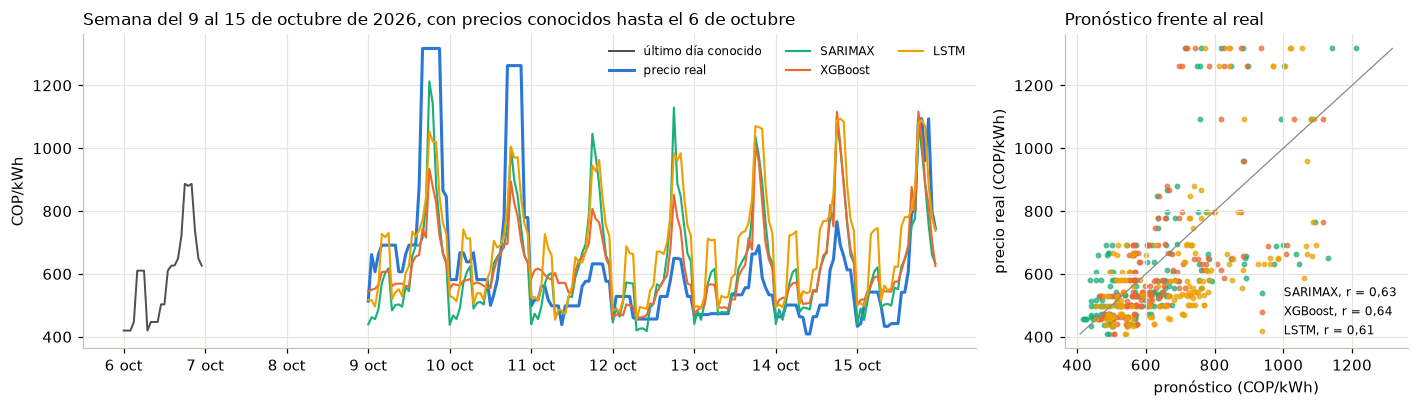

r de Pearson  MAPE (%)  MBE (COP/kWh)
semana                 modelo                                                
menos variable         SARIMAX                  0.11     14.48        -134.85
                       XGBoost                 -0.06     10.39         -70.12
                       LSTM                    -0.07     10.67         -78.75
                       ingenuo del día          0.16      8.91         -82.94
de variación mediana   SARIMAX                  0.18     37.17        -156.11
                       XGBoost                  0.59     29.96        -126.36
                       LSTM                     0.46     24.02         -87.53
                       ingenuo del día          0.17     43.49        -178.73
más variable           SARIMAX                  0.70     24.79         -24.57
                       XGBoost                  0.75     27.65         -10.04
                       LSTM                     0.56     28.76         -32.46
                       ingenuo del día          0.62     40.90          21.73
final, octubre de 2026 SARIMAX                  0.63     17.94           3.68
                       XGBoost                  0.64     15.94           3.13
                       LSTM                     0.61     23.22          66.81
                       ingenuo del día          0.60     18.71         -31.99

In [12]:
real_f = pd.read_csv(XGB / "precio_real_final.csv", parse_dates=["fecha_objetivo"])
px = pd.read_csv(XGB / "pronostico_final.csv", parse_dates=["origen", "fecha_objetivo"])
pl = pd.read_csv(LSTM / "pronostico_final.csv", parse_dates=["fecha_objetivo"])
ps = pd.read_csv(SAR / "pronostico_final.csv", parse_dates=["fecha"])
ps["fecha_objetivo"] = ps["fecha"] + pd.to_timedelta(ps["h"], unit="D")

final = (px[["origen", "fecha_objetivo", "hora", "precio_t", "precio_pron"]]
         .rename(columns={"origen": "t", "precio_t": "ingenuo del día", "precio_pron": "XGBoost"})
         .merge(pl[["fecha_objetivo", "hora", "precio_pron"]].rename(columns={"precio_pron": "LSTM"}), on=["fecha_objetivo", "hora"])
         .merge(ps.assign(SARIMAX=np.exp(ps["lp_hat"]))[["fecha_objetivo", "hora", "SARIMAX"]], on=["fecha_objetivo", "hora"])
         .merge(real_f.rename(columns={"precio_real": "real"}), on=["fecha_objetivo", "hora"]))
final["momento"] = final["fecha_objetivo"] + pd.to_timedelta(final["hora"] - 1, unit="h")
semanas["final, octubre de 2026"] = final
figura_semana(final, MODELOS, "Semana del 9 al 15 de octubre de 2026, con precios conocidos hasta el 6 de octubre")

filas = []
for nombre, s in semanas.items():
    for m in MODELOS + ["ingenuo del día"]:
        filas.append({"semana": nombre, "modelo": m, "r de Pearson": np.corrcoef(s["real"], s[m])[0, 1],
                      "MAPE (%)": 100 * np.mean(np.abs(s[m] - s["real"]) / s["real"]),
                      "MBE (COP/kWh)": np.mean(s[m] - s["real"])})
pd.DataFrame(filas).set_index(["semana", "modelo"]).round(2)

La semana menos variable (corte el 15 de septiembre de 2024) no es una semana tranquila típica: el
precio real se quedó entre 906 y 935 COP/kWh, pegado al precio de escasez de activación de ese mes,
932,5 COP/kWh. Los tres modelos pronosticaron la forma habitual del día, con subidas y bajadas que
no ocurrieron, y el mejor fue el ingenuo del día, que repite un día casi plano (MAPE de 8,9%). Con
un precio casi constante la correlación de Pearson no dice nada: queda entre $-0{,}07$ y $0{,}16$.
No fue la única vez: el precio quedó pegado a ese valor en 36 de las 1.087 semanas, casi todas con
corte en septiembre de 2023 y en septiembre de 2024. La serie de XM no tiene datos entre marzo de
2025 y abril de 2026, así que en ese tramo no se puede revisar.

En la semana de variación mediana (corte el 21 de enero de 2023) el precio real estuvo
alrededor de 382 COP/kWh, casi el doble de los 203 del último día conocido, y la LSTM fue la que
más se acercó: MAPE de 24,0%, frente a 30,0% de XGBoost, 37,2% de SARIMAX y 43,5% del ingenuo. En
la más variable (corte el 5 de agosto de 2025) los tres modelos siguieron los picos de cada noche,
pero ninguno se acercó al de 2.224 COP/kWh del 14 de agosto. Ahí la mejor correlación fue la de
XGBoost (0,75), seguida de SARIMAX (0,70); la LSTM tuvo 0,56.

En la semana final el orden fue otro: XGBoost tuvo el menor error (MAPE de 15,9%), después SARIMAX
(17,9%) y el ingenuo (18,7%), y la LSTM fue la peor (23,2%), con un MBE de 67 COP/kWh por encima
del precio real. Ninguna semana sola cambia el resultado del test, pero muestran que la ventaja
promedio no se cumple todas las semanas.

## 8. Por año y comparación directa

Primero, cada modelo contra el ingenuo del día en cada año del primer periodo, en la semana
completa y con el criterio de la tesis. El año es el del día del pronóstico.

In [13]:
t = d[d["periodo"] == "2023-2025"]
años = pd.concat({(a, m): criterio(g, m, {"h = 3 a 9": HS}) for a, g in t.groupby(t["fecha"].dt.year) for m in MODELOS},
                 names=["año", "modelo"]).droplevel("bloque")
años[["mejora (%)", "p"]].unstack("modelo").reindex(MODELOS, axis=1, level="modelo").round(3)

mejora (%)                       p               
modelo    SARIMAX XGBoost    LSTM SARIMAX XGBoost   LSTM
año                                                     
2023        4.162  12.861  21.566   0.005   0.001  0.000
2024        6.061   7.642   9.747   0.003   0.100  0.098
2025       10.370  15.266  12.224   0.000   0.000  0.007

En 2023 los tres modelos superan al ingenuo, aunque SARIMAX no llega al 5%. En 2024 es al revés:
SARIMAX mejora 6,1% con $p = 0{,}003$, mientras XGBoost y la LSTM mejoran más pero sin diferencia
significativa ($p$ cercano a 0,10). En 2025 los tres cumplen.

Tener menor RMSE no basta para decir que un modelo es mejor que otro. La prueba de Diebold-Mariano
entre cada par, con el error en logaritmo de toda la semana, dice si la diferencia es
significativa. En cada celda está el modelo con menor error y el valor $p$.

In [14]:
PARES = [("LSTM", "XGBoost"), ("LSTM", "SARIMAX"), ("XGBoost", "SARIMAX")]
casos = {p: g for p, g in d.groupby("periodo")} | {str(a): g for a, g in t.groupby(t["fecha"].dt.year)}

filas = []
for nombre, g in casos.items():
    fila = {"periodo": nombre}
    for a, b in PARES:
        tt, p = diebold_mariano(g["y"] - g[a], g["y"] - g[b], g["fecha"], max(HS) - 1 + 7)
        fila[f"{a} y {b}"] = f"{a if tt < 0 else b}, " + (f"p = {p:.3f}" if p >= 0.001 else "p < 0.001")
    filas.append(fila)
pd.DataFrame(filas).set_index("periodo")

,LSTM y XGBoost,LSTM y SARIMAX,XGBoost y SARIMAX
periodo,,,
2023-2025,"LSTM, p = 0.107","LSTM, p = 0.007","XGBoost, p = 0.011"
2026,"LSTM, p = 0.033","LSTM, p = 0.011","XGBoost, p = 0.062"
2023,"LSTM, p = 0.004","LSTM, p < 0.001","XGBoost, p = 0.003"
2024,"LSTM, p = 0.533","LSTM, p = 0.547","XGBoost, p = 0.707"
2025,"XGBoost, p = 0.331","LSTM, p = 0.655","XGBoost, p = 0.070"


La LSTM le gana a SARIMAX en los dos periodos ($p = 0{,}007$ y $0{,}011$) y XGBoost le gana a
SARIMAX en 2023-2025 ($p = 0{,}011$). Entre la LSTM y XGBoost la diferencia no es significativa en
2023-2025 ($p = 0{,}107$), pero sí en 2026 ($p = 0{,}033$).

Por años, los modelos solo se distinguen en 2023, cuando los tres pares son significativos. En
2024 no se distingue ningún par, y en 2025 XGBoost tiene menos error que la LSTM, aunque sin
diferencia significativa.

## 9. Nivel y forma del día

El error de cada día pronosticado se separa en dos partes: el nivel, que es el error en el promedio
de las 24 horas, y la forma, que es el error en cómo se reparte el precio entre las horas. Se
cumple que $\text{RMSE}^2 = \text{nivel}^2 + \text{forma}^2$.

In [15]:
def nivel_forma(g, pron):
    e = g["y"] - (g[pron] if pron else 0)
    medio = e.groupby([g["fecha"], g["h"]]).transform("mean")
    return pd.Series({"nivel": rmse(medio), "forma": rmse(e - medio), "RMSE": rmse(e)})


nf = pd.concat({(p, m): nivel_forma(g, None if m == "ingenuo del día" else m)
                for p, g in d.groupby("periodo") for m in MODELOS + ["ingenuo del día"]}, names=["periodo", "modelo"])
nf.unstack().reindex(MODELOS + ["ingenuo del día"], level="modelo").round(3)

nivel  forma   RMSE
periodo   modelo                              
2023-2025 SARIMAX          0.402  0.243  0.470
          XGBoost          0.385  0.221  0.443
          LSTM             0.347  0.249  0.427
          ingenuo del día  0.415  0.282  0.502
2026      SARIMAX          0.356  0.205  0.411
          XGBoost          0.341  0.193  0.392
          LSTM             0.274  0.216  0.350
          ingenuo del día  0.363  0.240  0.435

La LSTM es la que más reduce el error de nivel: en 2023-2025 baja de 0,415 (ingenuo) a 0,347,
mientras XGBoost llega a 0,385 y SARIMAX a 0,402. Esa era la razón para probar la red: XGBoost y
SARIMAX casi no mejoraban el nivel del día, y la LSTM se armó para usar lo que se publica antes que
el precio, como el despacho programado. En la forma del día el mejor sigue siendo XGBoost (0,221
frente a 0,249 de la LSTM).

## Hallazgos

1. Los tres modelos cumplen el criterio de la tesis en los dos periodos de test y en todos los
   bloques de horizontes. En logaritmo el orden es LSTM, XGBoost y SARIMAX: 14,9%, 11,6% y 6,4%
   de mejora en 2023-2025, y 19,7%, 10,0% y 5,6% en 2026.
2. La ventaja de la LSTM sobre XGBoost es significativa en 2026 ($p = 0{,}033$) pero no en
   2023-2025 ($p = 0{,}107$). La LSTM le gana a SARIMAX en los dos periodos, y XGBoost solo en
   2023-2025.
3. En pesos, con las métricas de Salazar-Peña et al. (2025), la LSTM también tiene el menor MAE,
   RMSE y MAPE en los dos periodos, pero las ventajas son menores: el skill score de la semana es
   7,1% y 8,8% para la LSTM, 5,8% y 6,4% para SARIMAX y 3,7% y 6,8% para XGBoost. Los tres modelos
   se quedan cortos en promedio por la vuelta de logaritmos a pesos. Corregir ese sesgo es un
   punto de mejora.
4. La ventaja de la LSTM y XGBoost está en los primeros días de la semana (skill score de 20% y 13%
   en $h = 3$ en 2023-2025). SARIMAX casi no baja el MAE del ingenuo, pero sí los errores grandes,
   y esa ventaja se mantiene en toda la semana: desde $h = 7$ es el de menor RMSE en pesos.
5. Por hora, la LSTM tiene el menor MAPE en casi todas las horas y XGBoost en el pico de la noche.
   En los mapas por horizonte y hora la LSTM es el mejor pronóstico en 126 de las 168 celdas en
   MAE.
6. La LSTM mejora sobre todo el nivel del día, que era lo que XGBoost y SARIMAX no lograban.
   XGBoost sigue siendo el mejor en la forma del día.
7. Los resultados cambian entre años y entre semanas. En 2024 ningún par de modelos se distingue y
   solo SARIMAX supera al ingenuo con significancia. En la semana del 9 al 15 de octubre de 2026
   la LSTM fue la peor de los tres.

## Referencias

- Diebold, F. y Mariano, R. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics*, 13(3), 253-263.
- Duan, N. (1983). Smearing estimate: a nonparametric retransformation method. *Journal of the American Statistical Association*, 78(383), 605-610.
- Newey, W. y West, K. (1987). A simple, positive semi-definite, heteroskedasticity and autocorrelation consistent covariance matrix. *Econometrica*, 55(3), 703-708.
- Salazar-Peña, N., Palma-Vergara, A., Montes-Vera, M., Vargas-Torres, M. A., Hernández Vanegas, R., Amador, M., Rojas, B., Salinas, A., Velasco, A., Tabares, A. y González-Mancera, A. (2025). Intra-day solar and power forecast for optimization of intraday market participation. *arXiv*, 2501.09551v3.